# Solve periodic viscous Burgers with Cole–Hopf transforation

We'll solve one initial-value problem and plot teh front:

$$
u_t+u u_x=\nu u_{xx},\qquad x\in\mathbb R/(2\pi\mathbb Z),
\qquad u(x,0)=-\sin x,\qquad \nu=0.025.
$$


The nice thing is with non zero viscosity Burgers equation is linearizable, and the analytic formula will give $u(x,t)$ directly at any time. 
The code evaluates the formula by quadrature in space.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from burgers import cole_hopf, grid, initial_data

nu = 0.025
n = 256
x = grid(n)  # [0, 2π), without duplicating the periodic endpoint
coefficients = np.array([[-1.0], [0.0]])

# set up the initial data
u0, primitive = initial_data(coefficients, x)
np.testing.assert_allclose(u0, -np.sin(x), atol=1e-14)
np.testing.assert_allclose(primitive, np.cos(x), atol=1e-14)
print(f"Mean of u₀ on the grid: {u0.mean():.2e}")

Mean of u₀ on the grid: 5.55e-17


## Cole-Hopf transform into heat equation

Define $\phi_0=e^{-F/(2\nu)}$, and solve $\phi_t=\nu\phi_{xx}$ with this initial condition. The heat flow preserves positivity, so $q=\log\phi$ is defined and satisfies $q_t=\nu(q_{xx}+q_x^2)$. Differentiating this identity in $x$ shows that $u=-2\nu q_x$ satisfies Burgers. At $t=0$, this formula returns $F'=u_0$.

Writing $G_t$ for the periodic heat kernel, we have $\phi=G_t*\phi_0$. Moving the derivative in $\phi_x$ onto the initial data gives $\phi'_0=-u_0\phi_0/(2\nu)$, and hence

$$
u(x,t)
=\frac{\bigl[G_t*(u_0\phi_0)\bigr](x)}
       {\bigl[G_t*\phi_0\bigr](x)}.
$$

This is the formula implemented by `cole_hopf`. The function samples the two convolutions on a finer integration grid and truncates the Gaussian image sum

$$
G_t(s)=\frac{1}{\sqrt{4\pi\nu t}}\sum_{m\in\mathbb Z}
\exp\!\left(-\frac{(s+2\pi m)^2}{4\nu t}\right).
$$

The heat-kernel normalization and the uniform quadrature spacing cancel in the quotient. It rescales $\phi_0$ by a constant before exponentiating to keep the intermediate values bounded. The same constant appears in both integrals and cancels.

In [2]:
log_phi0 = -primitive / (2 * nu)
phi0_scaled = np.exp(log_phi0 - log_phi0.max())
print(f"Rescaled heat initial data: [{phi0_scaled.min():.2e}, {phi0_scaled.max():.2f}]")

Rescaled heat initial data: [4.25e-18, 1.00]


## Solve transformed equation

Call `cole_hopf(coefficients, t, n=n, nu=nu)` once per time. Each call returns the solution on the same $n$ output points. For plotting, shift the periodic grid to $[-\pi,\pi]$ so the front at $x=0$ sits in the middle.

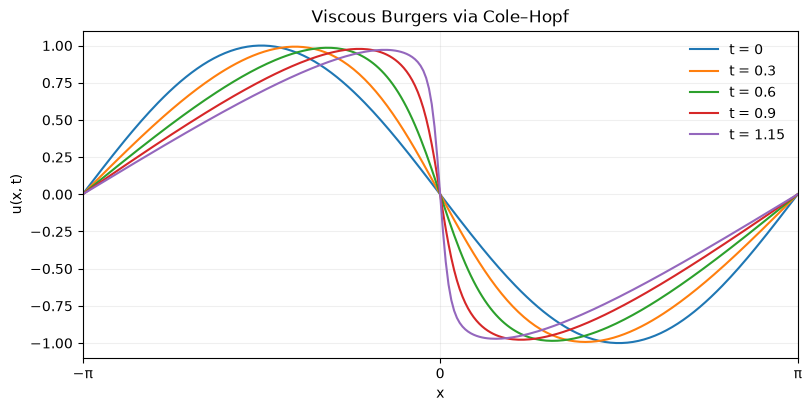

In [3]:
times = [0.0, 0.3, 0.6, 0.9, 1.15]
profiles = np.stack([cole_hopf(coefficients, t, n=n, nu=nu) for t in times])

x_plot = np.linspace(-np.pi, np.pi, n + 1)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for t, profile in zip(times, profiles):
    centered = np.fft.fftshift(profile)
    ax.plot(x_plot, np.r_[centered, centered[0]], label=f"t = {t:g}")

ax.set(
    title="Viscous Burgers via Cole–Hopf",
    xlabel="x", ylabel="u(x, t)", xlim=(-np.pi, np.pi),
    xticks=[-np.pi, 0, np.pi], xticklabels=["−π", "0", "π"],
)
ax.grid(alpha=0.2)
ax.legend(frameon=False)
plt.show()

# Verify conservation

Burgers in conservative form is $u_t=\partial_x(\nu u_x-u^2/2)$, so a periodic solution preserves its mean. Check that the evaluated profiles retain the mean of $u_0$. Then keep the output grid fixed and double the quadrature grid from $4n$ to $8n$ at $t=1.15$. The change in the output measures sensitivity to the integration grid for this example.

In [4]:
np.testing.assert_allclose(profiles[0], u0, atol=1e-14)

refined = cole_hopf(coefficients, times[-1], n=n, nu=nu, oversample=8)
mean_change = np.max(np.abs(profiles.mean(axis=1) - u0.mean()))
quadrature_change = np.max(np.abs(refined - profiles[-1]))
print(f"Largest sampled mean change:             {mean_change:.2e}")
print(f"Max final-time change with 8n quadrature: {quadrature_change:.2e}")

Largest sampled mean change:             1.11e-16
Max final-time change with 8n quadrature: 2.33e-15


# Reconstructing Burgers snapshots with conditional diffusion

Cole–Hopf gives the full solution for a specified initial condition. Now we'll generate solutions from many initial conditions, then hide all but the lowest Fourier modes of each snapshot. The DDPM will the be trained to draw possible completions given the retained modes.

## Low pass approximation to snapshots

Solve periodic viscous Burgers at physical time $t=0.75$ with viscosity $\nu=0.025$. Each example uses a different random mean-zero trigonometric initial condition. `cole_hopf` evaluates them in one batch. Use the first 1,536 examples for training and the remaining 48 for evaluation.

The observed signal is $y=P_{\leq 8}u$, and the missing residual is $r=u-y$. In the FFT, the low-pass projection simply zeros coefficients above mode 8. The inverse FFT gives the coarse observation back on the 256-point spatial grid.

Device: cuda | train/test: 1536/48 | grid: 256


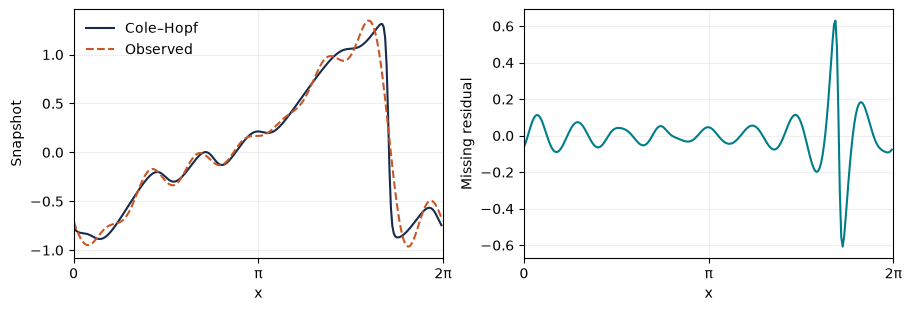

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.nn import functional as F

from burgers import CUTOFF, GRID, SNAPSHOT_TIME, cole_hopf, grid, random_initial_data
from diffusion import ResidualUNet, Schedule, high_pass, train_reconstructors

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(2)
rng = np.random.default_rng(7)
torch.manual_seed(7)


# try out a random initial condition

n_train, n_test = 1536, 48
updates, steps, draws_per_case = 1500, 64, 8
x = grid(GRID)
coefficients = random_initial_data(rng, n_train + n_test)
truth = cole_hopf(coefficients, SNAPSHOT_TIME)

low_spectrum = np.fft.rfft(truth, axis=-1)
low_spectrum[:, CUTOFF + 1:] = 0
observed = np.fft.irfft(low_spectrum, n=GRID, axis=-1)
residual = truth - observed
print(f"Device: {device} | train/test: {n_train}/{n_test} | grid: {GRID}")

def label_axis(ax, ylabel):
    ax.set(xlabel="x", ylabel=ylabel, xlim=(0, 2 * np.pi),
           xticks=[0, np.pi, 2 * np.pi], xticklabels=["0", "π", "2π"])
    ax.grid(alpha=0.2)

fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
i = 0  # One training snapshot
axes[0].plot(x, truth[i], color="#172b4d", label="Cole–Hopf")
axes[0].plot(x, observed[i], "--", color="#c95725", label="Observed")
axes[0].legend(frameon=False)
axes[1].plot(x, residual[i], color="#007e87")
label_axis(axes[0], "Snapshot")
label_axis(axes[1], "Missing residual")
plt.show()

## Normalize the observation and whiten the residual

Scale the observation and residual by their respective training RMS values, then divide each retained residual Fourier coefficient by its mode-wise training RMS. This gives the DDPM uniformly scaled frequencies.

In [6]:
def tensor(array):
    return torch.as_tensor(array, dtype=torch.float32, device=device)

low_scale = np.sqrt(np.mean(observed[:n_train] ** 2))
residual_scale = np.sqrt(np.mean(residual[:n_train] ** 2))
train_low = tensor(observed[:n_train] / low_scale)
train_residual = tensor(residual[:n_train] / residual_scale)
test_low = tensor(observed[n_train:] / low_scale)

train_spectrum = torch.fft.rfft(train_residual, norm="ortho")
train_spectrum[:, :CUTOFF + 1] = 0
mode_scale = train_spectrum.abs().square().mean(dim=0).sqrt()
mode_scale = mode_scale.clamp_min(1e-4 * mode_scale.max())
whitened = torch.fft.irfft(train_spectrum / mode_scale, n=GRID, norm="ortho")

def unwhiten(signal):
    spectrum = torch.fft.rfft(signal, norm="ortho") * mode_scale
    return residual_scale * torch.fft.irfft(spectrum, n=GRID, norm="ortho")

print(f"Observation RMS: {low_scale:.3f} | missing residual RMS: {residual_scale:.3f}")
torch.testing.assert_close(unwhiten(whitened[:4]), tensor(residual[:4]), rtol=1e-4, atol=1e-6)

Observation RMS: 0.730 | missing residual RMS: 0.084


# Noising

Let $z_0$ denote the clean whitened residual. For a diffusion step $j=1,\ldots,S$, write $a_j=\sqrt{\bar\alpha_j}$ and $b_j=\sqrt{1-\bar\alpha_j}$, where $\bar\alpha_j$ is the cumulative product of the schedule's $\alpha$'s. `Schedule.corrupt` computes both

$$
z_j=a_j z_0+b_j\epsilon,\qquad v_j=a_j\epsilon-b_j z_0.
$$

Here $\epsilon$ is standard Gaussian grid noise projected onto modes $|k|>8$. The observation $y$ stays fixed. The model predicts $v_j$, **velocity** in the diffusion models. From a velocity estimate $\widehat z_0=a_j z_j-b_j\widehat v_j$ can be recovered without dividing by $a_j$, which is tiny at the last step.

The code indexes noisy states from 0 through 63. Index 0 already has a little noise. These indices are independent of the physical Burgers time $t$.

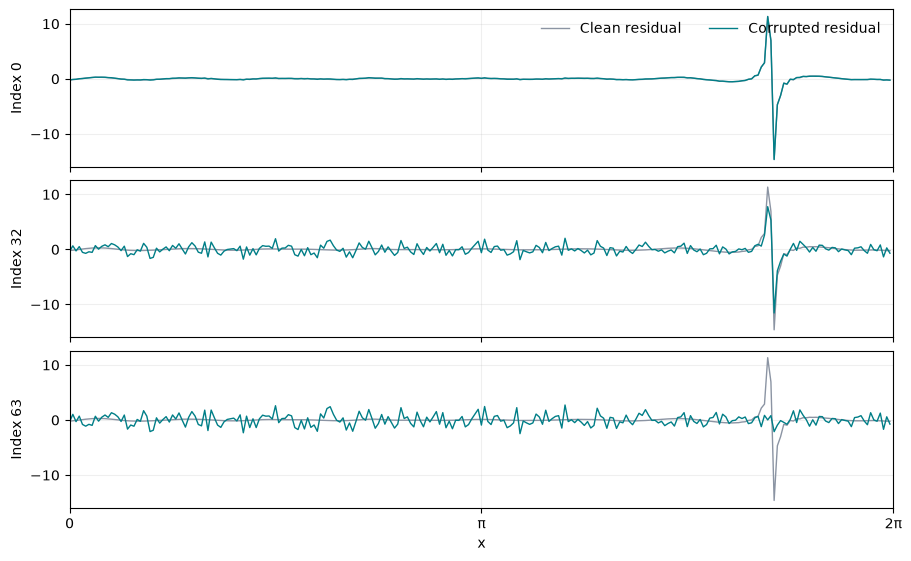

In [7]:
indices = torch.tensor([0, steps // 2, steps - 1], device=device)
clean = whitened[:1].expand(len(indices), -1)
noise = high_pass(torch.randn_like(clean[:1]), CUTOFF).expand_as(clean)
schedule = Schedule(steps, device)
noisy, velocity = schedule.corrupt(clean, noise, indices)

a = schedule.alpha_bar[indices, None].sqrt()
b = (1 - schedule.alpha_bar[indices, None]).sqrt()
torch.testing.assert_close(a * noisy - b * velocity, clean, rtol=1e-5, atol=1e-6)

fig, axes = plt.subplots(3, 1, figsize=(9, 5.5), sharex=True, sharey=True,
                         layout="constrained")
for ax, j, profile in zip(axes, indices.tolist(), noisy.cpu().numpy()):
    ax.plot(x, clean[0].cpu().numpy(), color="#8b94a3", lw=1, label="Clean residual")
    ax.plot(x, profile, color="#007e87", lw=1, label="Corrupted residual")
    label_axis(ax, f"Index {j}")
for ax in axes[:-1]:
    ax.set_xlabel("")
axes[0].legend(frameon=False, loc="upper right", ncol=2)
plt.show()

`ResidualUNet` stacks the noisy residual and observed profile as two channels, giving an input of shape `[batch, 2, 256]` internally. A separate sinusoidal embedding tells it the diffusion step. The network uses circular convolutions, pools to 128 points, and upsamples back to 256 points with a skip connection. Project its output onto the high modes before computing the velocity MSE.

In [8]:
# try out a single update
demo_model = ResidualUNet(steps).to(device)
optimizer = torch.optim.AdamW(demo_model.parameters(), lr=7e-4)

batch = torch.randint(n_train, (32,), device=device)
step = torch.randint(steps, (len(batch),), device=device)
clean_batch = whitened[batch]
noise_batch = high_pass(torch.randn_like(clean_batch), CUTOFF)
noisy_batch, target = schedule.corrupt(clean_batch, noise_batch, step)

optimizer.zero_grad()
prediction = high_pass(demo_model(noisy_batch, train_low[batch], step), CUTOFF)
loss = F.mse_loss(prediction, target)
loss.backward()
optimizer.step()

print(f"Predicted velocity shape: {tuple(prediction.shape)} | first batch loss: {loss.item():.3f}")

Predicted velocity shape: (32, 256) | first batch loss: 0.827


In [9]:
# train the ddpm

torch.manual_seed(8)
ddpm, baseline = train_reconstructors(
    train_low, train_residual, whitened, CUTOFF, schedule, updates)

Reconstruction step 250: velocity MSE 0.14, baseline MSE 0.352
Reconstruction step 500: velocity MSE 0.155, baseline MSE 0.364
Reconstruction step 750: velocity MSE 0.139, baseline MSE 0.235
Reconstruction step 1000: velocity MSE 0.246, baseline MSE 0.252
Reconstruction step 1250: velocity MSE 0.0967, baseline MSE 0.277
Reconstruction step 1500: velocity MSE 0.095, baseline MSE 0.271


## Reverse the diffusion process 

`schedule.sample` starts from projected Gaussian noise. At each reverse step it predicts velocity using the current state, the unchanged observation, and the step index. It recovers $\widehat z_0$ and uses the DDPM posterior mean, a weighted sum of the current state and $\widehat z_0$. It then adds projected Gaussian noise with the scheduled posterior variance. The last step has no added noise.

In code, the posterior-mean coefficients are `clean_weight` and `state_weight`. With $\beta_j=1-\alpha_j$ and $\bar\alpha_0=1$, the update is

$$
z_{j-1} =
\frac{\sqrt{\bar\alpha_{j-1}}\beta_j}{1-\bar\alpha_j}\,\widehat z_0
+
\frac{\sqrt{\alpha_j}(1-\bar\alpha_{j-1})}{1-\bar\alpha_j}\,z_j
+
\sqrt{\tilde\beta_j}\,\eta,
\quad
\tilde\beta_j = \beta_j\frac{1-\bar\alpha_{j-1}}{1-\bar\alpha_j}.
$$

The innovation $\eta$ is a fresh Gaussian draw projected onto the missing modes. At $j=1$ the formula returns $\widehat z_0$.

Repeat the same observation eight times to draw eight completions in parallel. Undo the whitening and add back the original coarse observation. Because every predicted residual lives in the high band, the reconstructed low coefficients agree with the measurements up to rounding error.

In [10]:
point_residuals, sampled_residuals = [], []
with torch.no_grad():
    for condition in test_low.split(8):
        zeros = torch.zeros_like(condition)
        step_zero = torch.zeros(len(condition), dtype=torch.long, device=device)
        point = high_pass(baseline(zeros, condition, step_zero), CUTOFF)
        point_residuals.append((residual_scale * point).cpu().numpy())

        repeated = condition.repeat_interleave(draws_per_case, dim=0)
        draws = schedule.sample(ddpm, repeated, CUTOFF)
        physical = unwhiten(draws).cpu().numpy()
        sampled_residuals.append(physical.reshape(len(condition), draws_per_case, GRID))

y_test, u_test = observed[n_train:], truth[n_train:]
point_prediction = y_test + np.concatenate(point_residuals)
samples = y_test[:, None, :] + np.concatenate(sampled_residuals)
ensemble_mean = samples.mean(axis=1)

coefficient_error = np.fft.rfft(samples - y_test[:, None, :], axis=-1) / GRID
max_observed_error = np.abs(coefficient_error[..., :CUTOFF + 1]).max()
assert max_observed_error < 1e-7
print(f"Ensemble shape: {samples.shape} | observed-mode error: {max_observed_error:.2e}")

Ensemble shape: (48, 8, 256) | observed-mode error: 2.20e-09


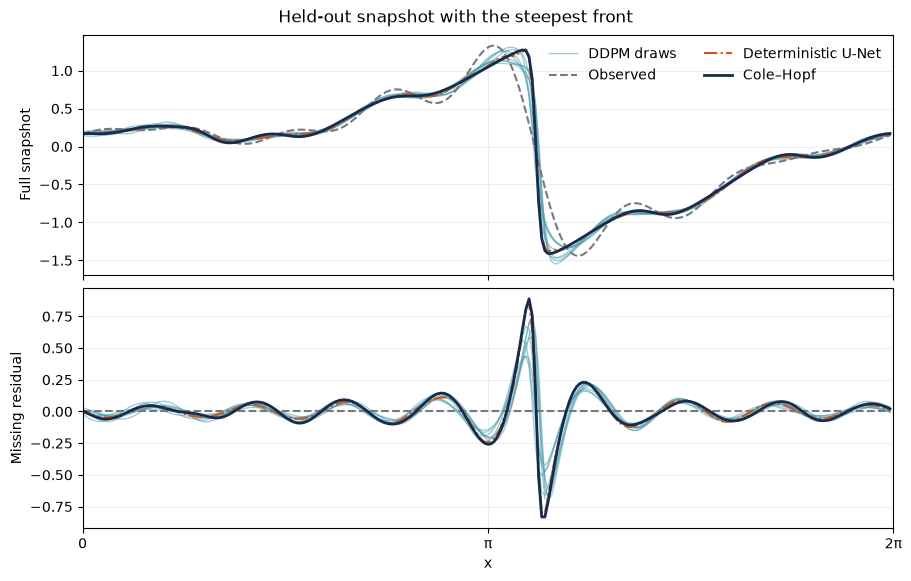

In [11]:
# Show the held-out snapshot with the steepest front.
k = np.fft.rfftfreq(GRID, d=1 / GRID)
ux = np.fft.irfft(1j * k * np.fft.rfft(u_test), n=GRID)
i = np.abs(ux).max(axis=-1).argmax()

fig, axes = plt.subplots(2, 1, figsize=(9, 5.7), sharex=True, layout="constrained")
for ax, offset, ylabel in zip(axes, [0, y_test[i]], ["Full snapshot", "Missing residual"]):
    for j, draw in enumerate(samples[i]):
        ax.plot(x, draw - offset, color="#479baa", alpha=0.5, lw=1,
                label="DDPM draws" if j == 0 else None)
    ax.plot(x, y_test[i] - offset, "--", color="#757983", label="Observed")
    ax.plot(x, point_prediction[i] - offset, "-.", color="#c95725", label="Deterministic U-Net")
    ax.plot(x, u_test[i] - offset, color="#172b4d", lw=2, label="Cole–Hopf")
    label_axis(ax, ylabel)
axes[0].set_xlabel("")
axes[0].legend(frameon=False, loc="upper right", ncol=2)
fig.suptitle("Held-out snapshot with the steepest front")
plt.show()

## Point accuracy and ensemble quality

RMSE compares point predictions to the true snapshots. For diffusion, the point prediction is the mean of the eight draws. Pointwise CRPS compares the predictive distribution with the true scalar value at each grid point. For an ensemble, it is the mean absolute draw-to-truth distance minus half the mean absolute distance between pairs of draws. A deterministic prediction gives a point mass, whose CRPS is its absolute error.

In [12]:
def rmse(estimate):
    return np.sqrt(np.mean((estimate - u_test) ** 2))

error_to_truth = np.abs(samples - u_test[:, None, :]).mean()
pairwise = np.abs(samples[:, :, None, :] - samples[:, None, :, :]).mean()
crps_ddpm = error_to_truth - 0.5 * pairwise
crps_baseline = np.abs(point_prediction - u_test).mean()

q10, q90 = np.quantile(samples, [0.1, 0.9], axis=1)
coverage = ((q10 <= u_test) & (u_test <= q90)).mean()
print(f"RMSE | low-pass {rmse(y_test):.4f} | baseline {rmse(point_prediction):.4f} "
      f"| DDPM mean {rmse(ensemble_mean):.4f}")
print(f"Pointwise CRPS | baseline {crps_baseline:.4f} | DDPM {crps_ddpm:.4f}")
print(f"Estimated 10th–90th percentile coverage: {coverage:.1%}")

RMSE | low-pass 0.0770 | baseline 0.0391 | DDPM mean 0.0440
Pointwise CRPS | baseline 0.0228 | DDPM 0.0183
Estimated 10th–90th percentile coverage: 60.5%


# PINNs

To do. 